<a href="https://colab.research.google.com/github/Ommi14/KanjiApp/blob/main/AItraining.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import tensorflow as tf
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train, x_test = x_train/255.0, x_test/255.0


In [9]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import *
model = Sequential([
    Flatten(input_shape=(28, 28)),
    Dense(114, activation='relu'),
    Dense(10, activation='softmax')
])



/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [10]:
from tensorflow.keras.losses  import SparseCategoricalCrossentropy
model.compile(optimizer='adam',
              loss=SparseCategoricalCrossentropy(),
              metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 114)            │        89,490 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,150 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 90,640 (354.06 KB)

 Trainable params: 90,640 (354.06 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
rounds = 14
history = model.fit(x_train, y_train, validation_data=[x_test, y_test], epochs=rounds)

Epoch 1/14
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9978 - loss: 0.0078 - val_accuracy: 0.9744 - val_loss: 0.1056
Epoch 2/14
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9974 - loss: 0.0084 - val_accuracy: 0.9798 - val_loss: 0.0930
Epoch 3/14
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9978 - loss: 0.0070 - val_accuracy: 0.9800 - val_loss: 0.0946
Epoch 4/14
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9984 - loss: 0.0062 - val_accuracy: 0.9798 - val_loss: 0.0978
Epoch 5/14
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9984 - loss: 0.0051 - val_accuracy: 0.9791 - val_loss: 0.0981
Epoch 6/14
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9984 - loss: 0.0051 - val_accuracy: 0.9778 - val_loss: 0.1111
Epoch 7/14
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9977 - loss: 0.0072 - val_accuracy: 0.9779 - val_loss: 0.1140
Epoch 8/14
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.9989 - loss: 0.0039 - 

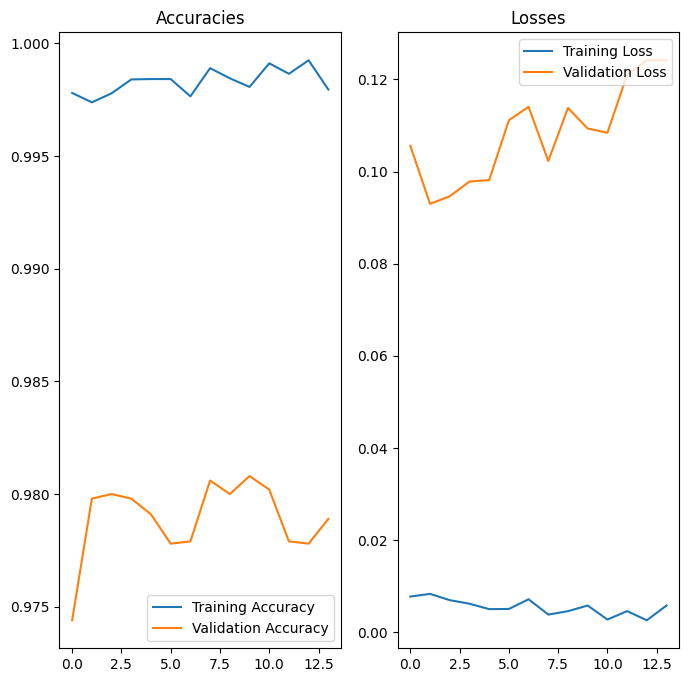

In [14]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(rounds)

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.title('Accuracies')
plt.legend(loc='lower right')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.title('Losses')
plt.legend(loc='upper right')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
[[2.6182685e-22 4.6445400e-26 9.1116054e-15 2.5873665e-17 1.0000000e+00
  3.2309142e-20 6.3332499e-23 1.9536195e-18 3.0054640e-14 5.3289362e-10]]


Text(0.5, 1.0, 'Result: 4')

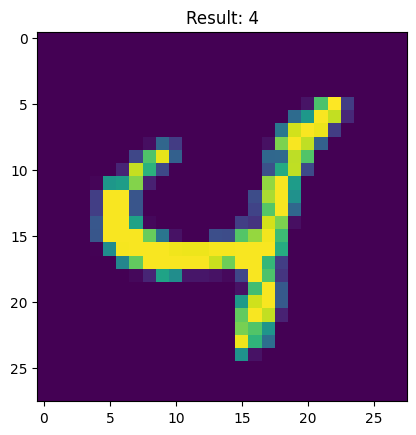

In [19]:
import numpy as np
test_im = np.reshape(x_test[67], (1, 28, 28))
res = model.predict(test_im)
print(res)
r_real = np.argmax(res)
plt.imshow(x_test[67])
plt.title('Result: '+str(r_real))

In [21]:
model.save('ann_workshop1.keras')